<a href="https://colab.research.google.com/github/matiusvera611-sudo/POO-T3/blob/main/Big_Data_Costa_y_Sierra_SRL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pyspark -q

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, countDistinct, date_format, to_date
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("Costa y Sierra SRL") \
    .master("local[2]") \
    .getOrCreate()

print("Entorno Big Data listo")
print("Versión de Spark:", spark.version)

Entorno Big Data listo
Versión de Spark: 4.0.5


In [5]:
from google.colab import files

files.upload()

Saving DetallePedido.csv to DetallePedido.csv
Saving Pedido.csv to Pedido.csv
Saving Local.csv to Local.csv
Saving Plato.csv to Plato.csv


{'DetallePedido.csv': b'\xef\xbb\xbf1;1;1;1;14.00;14.00\r\n2;1;4;1;34.00;34.00\r\n3;1;23;1;85.00;85.00\r\n4;1;28;1;5.00;5.00\r\n5;1;30;1;22.00;22.00\r\n6;2;4;1;34.00;34.00\r\n7;2;8;1;32.00;32.00\r\n8;2;24;1;30.00;30.00\r\n9;2;26;1;7.00;7.00\r\n10;2;28;1;5.00;5.00\r\n11;2;35;1;9.00;9.00\r\n12;3;4;1;34.00;34.00\r\n13;3;8;1;32.00;32.00\r\n14;3;20;1;42.00;42.00\r\n15;3;30;1;22.00;22.00\r\n16;4;13;1;13.00;13.00\r\n17;4;18;2;34.00;68.00\r\n18;4;26;2;7.00;14.00\r\n19;5;5;1;42.00;42.00\r\n20;5;15;1;22.00;22.00\r\n21;5;27;1;9.00;9.00\r\n22;5;28;1;5.00;5.00\r\n23;6;4;1;34.00;34.00\r\n24;6;8;1;32.00;32.00\r\n25;6;9;1;26.00;26.00\r\n26;6;26;1;7.00;7.00\r\n27;6;27;1;9.00;9.00\r\n28;6;28;1;5.00;5.00\r\n29;6;34;1;12.00;12.00\r\n30;7;17;1;30.00;30.00\r\n31;7;20;1;42.00;42.00\r\n32;7;29;1;12.00;12.00\r\n33;8;1;1;14.00;14.00\r\n34;8;24;1;30.00;30.00\r\n35;9;8;1;32.00;32.00\r\n36;9;11;1;24.00;24.00\r\n37;9;19;1;30.00;30.00\r\n38;9;30;1;22.00;22.00\r\n39;10;4;1;28.90;28.90\r\n40;10;9;1;26.00;26.00\r\n41;1

In [6]:
# Cargar archivos CSV separados por punto y coma

df_pedidos = spark.read.csv(
    "Pedido.csv",
    sep=";",
    header=False,
    inferSchema=True
).toDF(
    "IdPedido",
    "IdLocal",
    "FechaPedido",
    "Estado",
    "Total"
)

df_detalles = spark.read.csv(
    "DetallePedido.csv",
    sep=";",
    header=False,
    inferSchema=True
).toDF(
    "IdDetallePedido",
    "IdPedido",
    "IdPlato",
    "Cantidad",
    "PrecioUnitario",
    "Subtotal"
)

df_platos = spark.read.csv(
    "Plato.csv",
    sep=";",
    header=False,
    inferSchema=True
).toDF(
    "IdPlato",
    "NombrePlato"
)

df_locales = spark.read.csv(
    "Local.csv",
    sep=";",
    header=False,
    inferSchema=True
).toDF(
    "IdLocal",
    "NombreLocal"
)

print("=== DATOS SIMULADOS CARGADOS ===")

print("Pedidos:", df_pedidos.count())
print("Detalles:", df_detalles.count())
print("Platos:", df_platos.count())
print("Locales:", df_locales.count())

=== DATOS SIMULADOS CARGADOS ===
Pedidos: 3227
Detalles: 12419
Platos: 35
Locales: 3


In [7]:
print("=== PEDIDOS ===")
df_pedidos.show(5)
df_pedidos.printSchema()

print("=== DETALLE DE PEDIDOS ===")
df_detalles.show(5)

print("=== PLATOS ===")
df_platos.show(5)

print("=== LOCALES ===")
df_locales.show()

=== PEDIDOS ===
+--------+-------+-----------+---------+-----+
|IdPedido|IdLocal|FechaPedido|   Estado|Total|
+--------+-------+-----------+---------+-----+
|       1|      1| 2025-09-01|Entregado|160.0|
|       2|      1| 2025-09-01|Entregado|117.0|
|       3|      1| 2025-09-01|Entregado|130.0|
|       4|      1| 2025-09-01|Entregado| 95.0|
|       5|      1| 2025-09-01|Entregado| 78.0|
+--------+-------+-----------+---------+-----+
only showing top 5 rows
root
 |-- IdPedido: integer (nullable = true)
 |-- IdLocal: integer (nullable = true)
 |-- FechaPedido: date (nullable = true)
 |-- Estado: string (nullable = true)
 |-- Total: double (nullable = true)

=== DETALLE DE PEDIDOS ===
+---------------+--------+-------+--------+--------------+--------+
|IdDetallePedido|IdPedido|IdPlato|Cantidad|PrecioUnitario|Subtotal|
+---------------+--------+-------+--------+--------------+--------+
|              1|       1|      1|       1|          14.0|    14.0|
|              2|       1|      4| 

In [8]:
from pyspark.sql.functions import col

# Eliminar duplicados y valores nulos

df_pedidos = df_pedidos.dropDuplicates(["IdPedido"]) \
    .dropna(subset=["IdPedido", "IdLocal", "FechaPedido", "Estado"])

df_detalles = df_detalles.dropDuplicates(["IdDetallePedido"]) \
    .dropna(subset=["IdDetallePedido", "IdPedido", "IdPlato",
                    "Cantidad", "Subtotal"])

df_platos = df_platos.dropDuplicates(["IdPlato"])

df_locales = df_locales.dropDuplicates(["IdLocal"])

# Excluir pedidos cancelados

df_pedidos = df_pedidos.filter(
    col("Estado") != "Cancelado"
)

# Filtrar cantidades e importes válidos

df_detalles = df_detalles.filter(
    (col("Cantidad") > 0) &
    (col("Subtotal") >= 0)
)

print("Limpieza de datos completada correctamente")

print("Pedidos válidos:", df_pedidos.count())
print("Detalles válidos:", df_detalles.count())

Limpieza de datos completada correctamente
Pedidos válidos: 3103
Detalles válidos: 12419


In [9]:
df_ventas = df_pedidos \
    .join(df_detalles, "IdPedido") \
    .join(df_platos, "IdPlato") \
    .join(df_locales, "IdLocal")

df_ventas = df_ventas.select(
    "IdPedido",
    "FechaPedido",
    "NombreLocal",
    "NombrePlato",
    "Cantidad",
    "Subtotal"
)

df_ventas.cache()

print("=== DATOS INTEGRADOS ===")
print("Total de registros:", df_ventas.count())

df_ventas.show(10, truncate=False)

=== DATOS INTEGRADOS ===
Total de registros: 11932
+--------+-----------+---------------------------------+--------------------+--------+--------+
|IdPedido|FechaPedido|NombreLocal                      |NombrePlato         |Cantidad|Subtotal|
+--------+-----------+---------------------------------+--------------------+--------+--------+
|36      |2025-09-06 |Costa y Sierra - Cajamarca Centro|Caldo de Gallina    |1       |22.0    |
|121     |2025-09-18 |Costa y Sierra - Cajamarca Centro|Café Pasado         |1       |5.0     |
|124     |2025-09-18 |Costa y Sierra - Cajamarca Centro|Chicharrón de Cerdo |1       |28.0    |
|130     |2025-09-19 |Costa y Sierra - Cajamarca Centro|Cecina con Yuca     |1       |34.0    |
|216     |2025-09-30 |Costa y Sierra - Cajamarca Centro|Chicha Morada (vaso)|1       |7.0     |
|281     |2025-10-09 |Costa y Sierra - Cajabamba       |Caldo de Gallina    |1       |22.0    |
|317     |2025-10-12 |Costa y Sierra - Cajabamba       |Tamal Serrano       |2       

In [10]:
df_ingresos = df_ventas.groupBy("NombreLocal") \
    .agg(sum("Subtotal").alias("IngresosTotales")) \
    .orderBy(col("IngresosTotales").desc())

print("=== INGRESOS TOTALES POR SEDE ===")

df_ingresos.show(truncate=False)

=== INGRESOS TOTALES POR SEDE ===
+---------------------------------+-----------------+
|NombreLocal                      |IngresosTotales  |
+---------------------------------+-----------------+
|Costa y Sierra - Cajamarca Centro|150339.1999999999|
|Costa y Sierra - Cajabamba       |96427.19999999998|
|Costa y Sierra - Trujillo        |80909.99999999999|
+---------------------------------+-----------------+



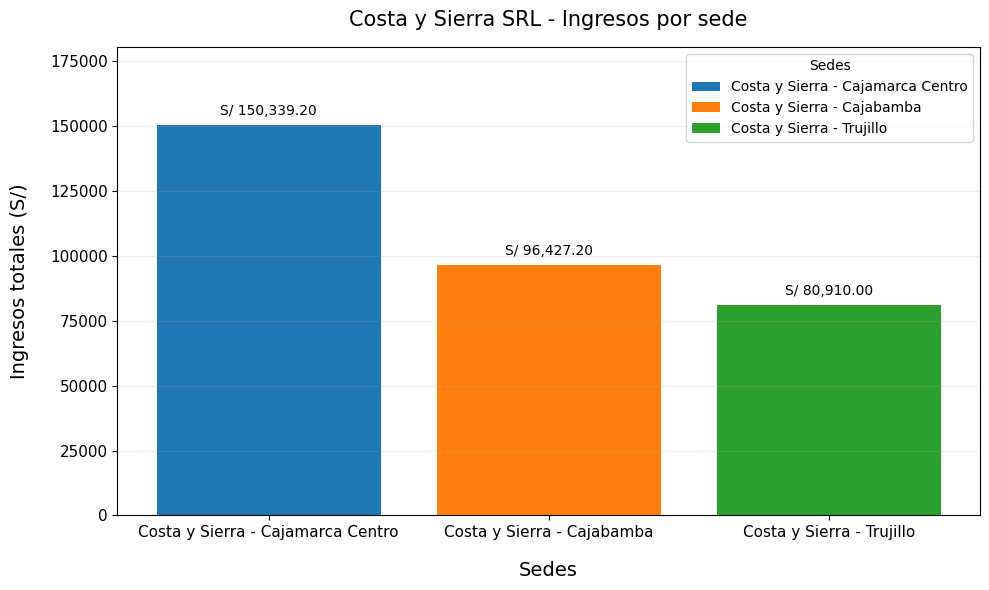

In [21]:
datos = df_ingresos.collect()

sedes = [fila["NombreLocal"] for fila in datos]
ingresos = [float(fila["IngresosTotales"]) for fila in datos]

plt.figure(figsize=(10, 6))

# Usamos colores diferenciados para cada sede en el primer gráfico
colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]

barras = plt.bar(sedes, ingresos, color=colores)

plt.bar_label(
    barras,
    labels=[f"S/ {x:,.2f}" for x in ingresos],
    padding=5
)

# Leyenda solo para este primer gráfico
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colores[i], label=sedes[i]) for i in range(len(sedes))]
plt.legend(handles=legend_elements, title="Sedes", loc="upper right")

plt.title("Costa y Sierra SRL - Ingresos por sede", fontsize=15, pad=15)
plt.xlabel("Sedes", fontsize=14, labelpad=15)
plt.ylabel("Ingresos totales (S/)", fontsize=14, labelpad=15)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.ylim(0, max(ingresos) * 1.20)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [22]:
from pyspark.sql.functions import date_format, to_date, countDistinct

df_mensual = df_pedidos.withColumn(
    "Periodo",
    date_format(to_date("FechaPedido"), "yyyy-MM")
)

df_mensual = df_mensual.groupBy("Periodo") \
    .agg(countDistinct("IdPedido").alias("TotalPedidos")) \
    .orderBy("Periodo")

print("=== PEDIDOS POR MES ===")

df_mensual.show()

=== PEDIDOS POR MES ===
+-------+------------+
|Periodo|TotalPedidos|
+-------+------------+
|2025-09|         209|
|2025-10|         256|
|2026-04|         371|
|2026-05|         427|
|2026-06|         345|
|2026-07|         435|
|2026-08|         437|
|2026-09|         439|
|2026-10|         184|
+-------+------------+



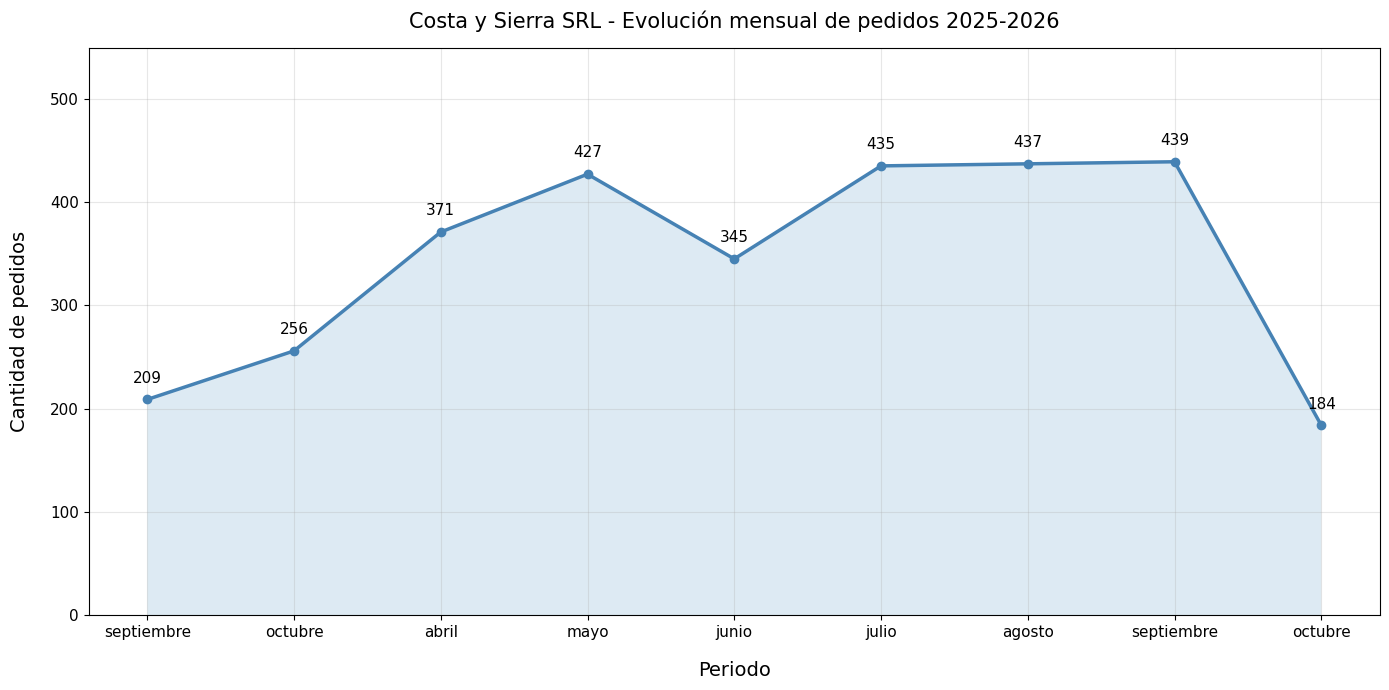

In [23]:
datos = df_mensual.collect()

# Diccionario para traducir el número de mes a español
meses_es = {
    "01": "enero", "02": "febrero", "03": "marzo", "04": "abril",
    "05": "mayo", "06": "junio", "07": "julio", "08": "agosto",
    "09": "septiembre", "10": "octubre", "11": "noviembre", "12": "diciembre"
}

# Mantener el orden de los periodos pero preparar las etiquetas de los meses
periodos_originales = [fila["Periodo"] for fila in datos]
meses_etiquetas = []
for p in periodos_originales:
    _, mes = p.split("-")
    meses_etiquetas.append(meses_es[mes])

pedidos = [fila["TotalPedidos"] for fila in datos]
x_indices = list(range(len(pedidos)))

plt.figure(figsize=(14, 7))

# Graficamos usando índices numéricos para asegurar que la línea y los puntos sigan el orden secuencial
plt.plot(
    x_indices, pedidos,
    marker="o",
    linewidth=2.5,
    color="steelblue"
)

plt.fill_between(x_indices, pedidos, alpha=0.15)

for i, total in enumerate(pedidos):
    plt.annotate(
        str(total),
        (x_indices[i], total),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=11
    )

plt.title("Costa y Sierra SRL - Evolución mensual de pedidos 2025-2026", fontsize=15, pad=15)
plt.xlabel("Periodo", fontsize=14, labelpad=15)
plt.ylabel("Cantidad de pedidos", fontsize=14, labelpad=15)

# Mapeamos los índices numéricos de vuelta a los nombres de los meses
plt.xticks(ticks=x_indices, labels=meses_etiquetas, rotation=0, fontsize=11)
plt.yticks(fontsize=11)

plt.ylim(0, max(pedidos) * 1.25)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
df_ranking = df_ventas.groupBy("NombrePlato") \
    .agg(sum("Cantidad").alias("UnidadesVendidas")) \
    .orderBy(
        col("UnidadesVendidas").desc(),
        col("NombrePlato").asc()
    ).limit(10)

print("=== TOP 10 PLATOS MÁS VENDIDOS ===")

df_ranking.show(truncate=False)

=== TOP 10 PLATOS MÁS VENDIDOS ===
+--------------------+----------------+
|NombrePlato         |UnidadesVendidas|
+--------------------+----------------+
|Ceviche de Pescado  |934             |
|Lomo Saltado        |889             |
|Gaseosa Personal    |779             |
|Chicha Morada (vaso)|770             |
|Limonada Frozen     |614             |
|Caldo de Gallina    |566             |
|Ají de Gallina      |564             |
|Cecina con Yuca     |539             |
|Arroz con Pollo     |481             |
|Trucha Frita        |481             |
+--------------------+----------------+



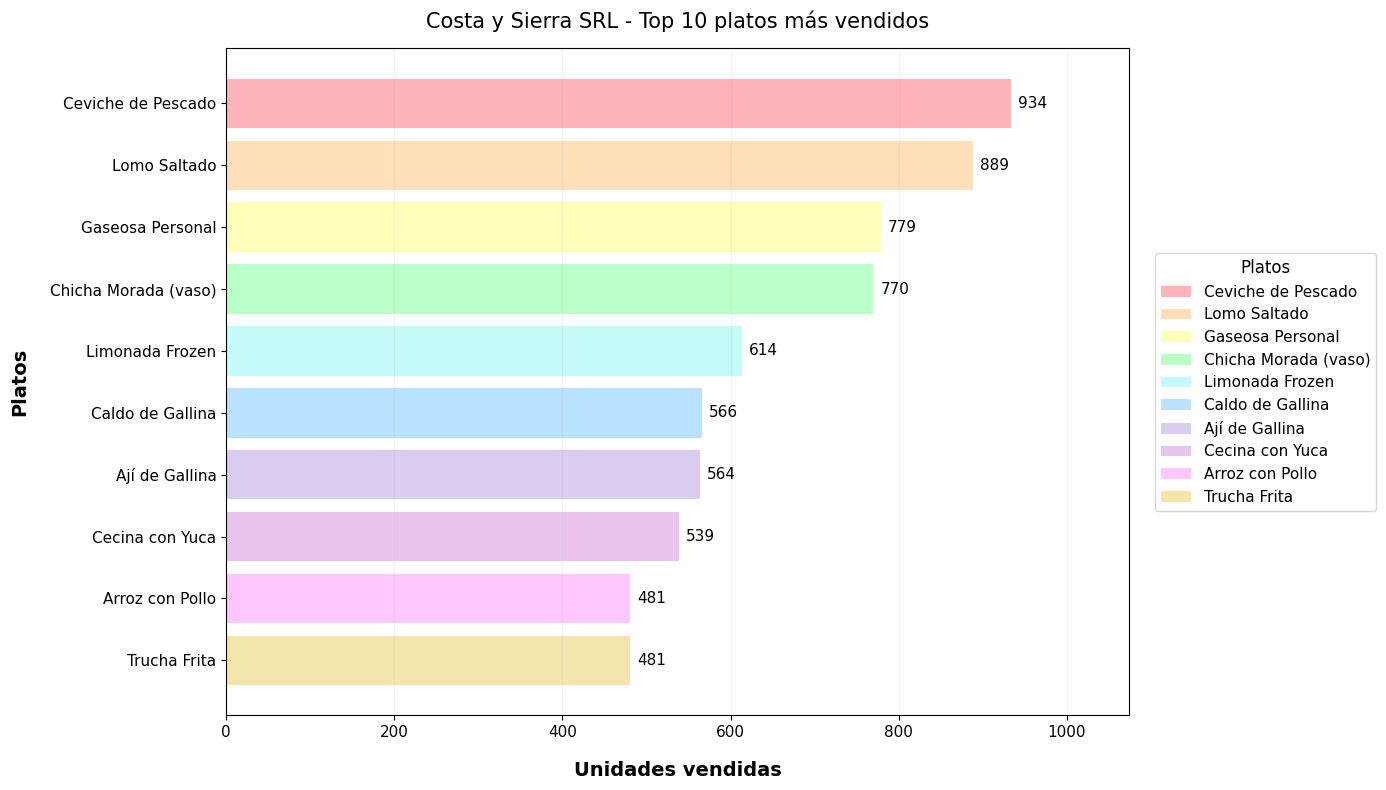

In [31]:
datos = df_ranking.collect()

platos = [fila["NombrePlato"] for fila in datos]
unidades = [fila["UnidadesVendidas"] for fila in datos]

plt.figure(figsize=(14, 8))

# Escala de colores pasteles diferenciados y ordenados estéticamente (Rojo/Rosa -> Naranja -> Amarillo -> Verde -> Azul -> Violeta)
colores_pasteles_escala = [
    "#ffb3ba",  # Rojo / Rosa pastel
    "#ffdfba",  # Naranja pastel
    "#ffffba",  # Amarillo pastel
    "#baffc9",  # Verde pastel
    "#c4faf8",  # Turquesa / Verde agua
    "#bae1ff",  # Azul pastel
    "#dbcdf0",  # Lavanda / Azul lila
    "#e8c4ec",  # Violeta suave
    "#ffc6ff",  # Fucsia claro
    "#f3e5ab"   # Crema / Vainilla
]

barras = plt.barh(platos, unidades, color=colores_pasteles_escala[:len(platos)])

plt.bar_label(barras, padding=5, fontsize=11)
plt.gca().invert_yaxis()

# Crear la leyenda con los mismos colores ordenados en escala pastel
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colores_pasteles_escala[i], label=platos[i]) for i in range(len(platos))]
plt.legend(handles=legend_elements, title="Platos", loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=11, title_fontsize=12)

plt.title("Costa y Sierra SRL - Top 10 platos más vendidos", fontsize=15, pad=15)
plt.xlabel("Unidades vendidas", fontsize=14, labelpad=15, weight="bold")
plt.ylabel("Platos", fontsize=14, labelpad=15, weight="bold")
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.xlim(0, max(unidades) * 1.15)
plt.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()

In [ ]:
import time
import builtins
from pyspark.sql.functions import sum, count

# Prueba de escalabilidad: volumen base y 10 veces

for factor in [1, 10]:

    df_prueba = df_ventas.crossJoin(spark.range(factor))

    inicio = time.perf_counter()

    resultado = df_prueba.groupBy("NombreLocal").agg(
        sum("Subtotal").alias("Ingresos"),
        count("*").alias("Registros")
    ).collect()

    fin = time.perf_counter()

    total_registros = builtins.sum(
        fila["Registros"] for fila in resultado
    )

    print(f"=== PRUEBA {factor}x ===")
    print("Registros procesados:", total_registros)
    print("Tiempo:", round(fin - inicio, 4), "segundos")
    print("-" * 40)

=== PRUEBA 1x ===
Registros procesados: 11932
Tiempo: 4.5258 segundos
----------------------------------------
=== PRUEBA 10x ===
Registros procesados: 119320
Tiempo: 5.3064 segundos
----------------------------------------


In [ ]:
print("=== VALIDACIÓN DE RESULTADOS PYSPARK ===")

df_ingresos.show(truncate=False)

=== VALIDACIÓN DE RESULTADOS PYSPARK ===
+---------------------------------+-----------------+
|NombreLocal                      |IngresosTotales  |
+---------------------------------+-----------------+
|Costa y Sierra - Cajamarca Centro|150339.1999999999|
|Costa y Sierra - Cajabamba       |96427.19999999998|
|Costa y Sierra - Trujillo        |80909.99999999999|
+---------------------------------+-----------------+

